In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv, j0, j1, jv, jvp
from scipy.signal import savgol_filter

import matplotlib.pyplot as plt
import matplotlib.colors as colors


from transmission_maps import point_signal_SBW, point_signal_DBW
from scenery_generation import generate_scenery
from cross_correlation import cross_corr_coeff, cross_corr_coeff_merged

from matplotlib.colors import LogNorm
from colormap import full_map, pos_map, neg_map


In [2]:
# =================== general parameters ====================
# not relevant for the NN
Npix = 300
fov_as = 0.3 # [arcsec]
fov_rad =  fov_as * (np.pi / 180) / 3600 # [rad]

time = 30 * 3600 # [s]
read_time = 1000 #[s]
N = int(time / read_time)

R = 40
lambda_min = 4e-6
lambda_max = 18.5e-6

alpha = np.linspace(-fov_as, fov_as, Npix)
beta = np.linspace(-fov_as, fov_as, Npix)
ALPHA, BETA = np.meshgrid(alpha, beta, indexing='ij') # [as]


# ================== Instrument parameters ===================
# as info for NN but not being retrieved (only input, not output)
baseline =20 # [m]
t = np.linspace(0, time, N)
Omega = (2 / time) * 2 * np.pi #  [rad/s]
lambdas = np.logspace(np.log10(lambda_min), np.log10(lambda_max), int(R * np.log(lambda_max/lambda_min) + 0.5), base = 10)

In [3]:
T_SBW_lambda_scenery = point_signal_SBW(t, ALPHA, BETA, baseline, lamda_ref=lambdas, Omega = Omega)

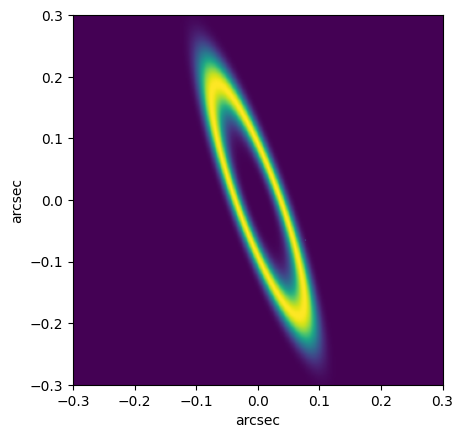

In [4]:
# =================== Scenery parameters ====================
sep_planet_as = 0.1 # [arcsec]
phase_planet = 50 # [deg] [0,180) for single-bracewell, [0,360) for double-bracewell
flux_planet = 1e6 

inc_exozodi = 80 # [deg] [0,90]
phi_exozodi = 20 # [deg] [0,180) for single-bracewell, [0,360) for double-bracewell
r0_exozodi = 0.2

sig_exozodi = 0.04
flux_exozodi = 1e6

# =================== Generate the scenery =============================== 
IM = generate_scenery(sep_planet_as, phase_planet, flux_planet, inc_exozodi, phi_exozodi, r0_exozodi, sig_exozodi, flux_exozodi, ALPHA, BETA)

# ============== Plot the Scenery ==============================
plt.figure()
plt.imshow(IM, cmap='viridis', extent = (-fov_as, fov_as, -fov_as, fov_as))
plt.xlabel("arcsec")
plt.ylabel("arcsec")
plt.show()
plt.close()

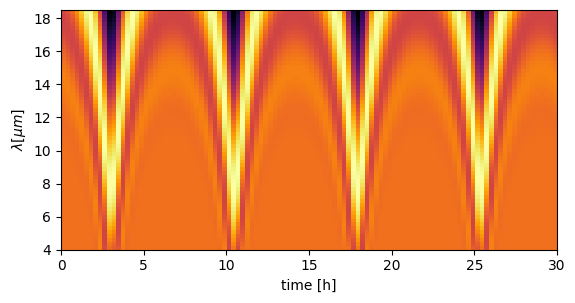

In [5]:

signal = np.sum(T_SBW_lambda_scenery * IM[None, None, :, :], axis=(2,3)) 

# ================== Plot signal ==================
plt.figure()
plt.imshow(signal, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6),  cmap='inferno', origin = 'lower')
plt.xlabel("time [h]")
plt.ylabel(r"$\lambda [\mu m]$")
plt.show()
plt.close()

## Signal Processing

### Time dependent Transmission Map for the signal of the entire field of view

In [6]:


def combined_plot(IM, proj, proj_merged, vmin = None, vmax = None,  cmap = 'viridis'):


    fig, ax = plt.subplots(1, 7, figsize = (15, 8))
    N_l = len(ax)-2
    step = int(len(lambdas)/N_l)
    print(N_l, step)
    for i in range(N_l):
        ax[i].imshow(proj[i*step,:,:], extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap,  vmin=vmin, vmax=vmax)
        ax[i].set_title(rf"$\lambda$ = {np.round(1e6*lambdas[i*step],2)} $\mu m$")
    ax[-2].imshow(proj_merged, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap,  vmin=vmin, vmax=vmax)
    ax[-1].imshow(IM, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = 'inferno')
    ax[-2].set_title(r"All $\lambda$")
    ax[-1].set_title(r"Target Image")
    for i in range(ax.shape[0]):
        ax[i].set_xticks([])
        ax[i].set_yticks([])
    plt.show()
    plt.close()


5 12


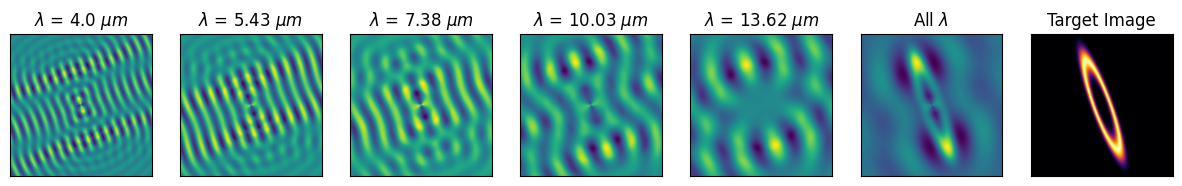

In [7]:
proj = cross_corr_coeff(signal, T_SBW_lambda_scenery, centered = True)
proj_merged = cross_corr_coeff_merged(signal, T_SBW_lambda_scenery, centered = True)
#combined_plot(IM,proj, proj_merged, vmin=-1, vmax =1, cmap = 'coolwarm_r')
combined_plot(IM,proj, proj_merged)


# Plots

In [8]:

baseline = 8
t = np.linspace(0, 2*np.pi, 2000)/Omega

idx_alpha = 30*3
idx_beta = 30*3
idx_lambda = 15
idx_time = 0
r0 = np.sqrt(alpha[idx_alpha]**2 + beta[idx_beta]**2) # [ arcsec ]
#r0 = 0.07
circle = np.asarray([np.sin(np.linspace(0, 2*np.pi, 100)),  np.cos(np.linspace(0, 2*np.pi, 100))])* r0


inv_range = baseline / lambdas / 3600 / 180 * np.pi * r0
inv_l = inv_range[idx_lambda] 

S_SBW_lambda_scenery = point_signal_SBW(t, alpha[idx_alpha], beta[idx_beta], baseline, lamda_ref=lambdas, Omega = Omega)
T_SBW_lambda_scenery = point_signal_SBW(t[idx_time], ALPHA, BETA, baseline, lamda_ref=lambdas[idx_lambda], Omega = Omega)
S_DBW_lambda_scenery = point_signal_DBW(t, alpha[idx_alpha], beta[idx_beta], baseline, lamda_ref=lambdas, Omega = Omega, q = 6)
T_DBW_lambda_scenery = point_signal_DBW(t[idx_time], ALPHA, BETA, baseline, lamda_ref=lambdas[idx_lambda], Omega = Omega, q = 6)

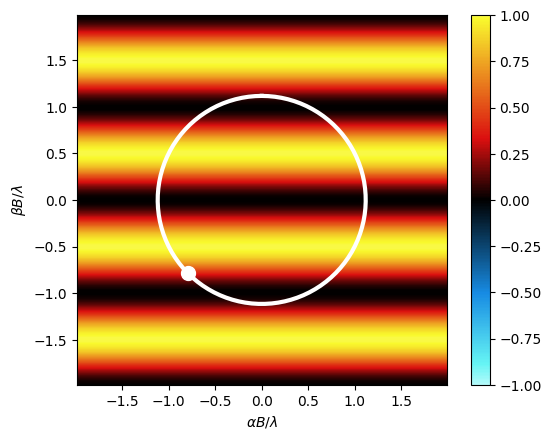

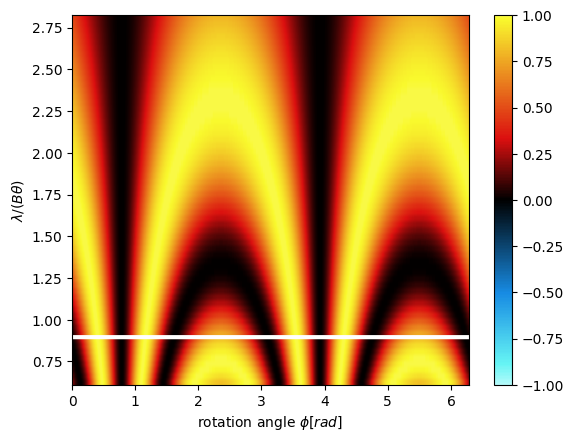

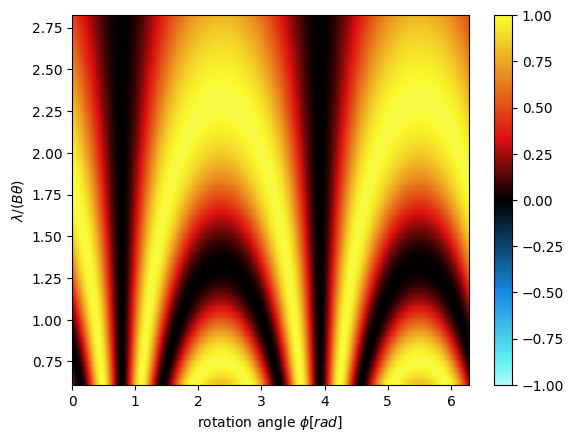

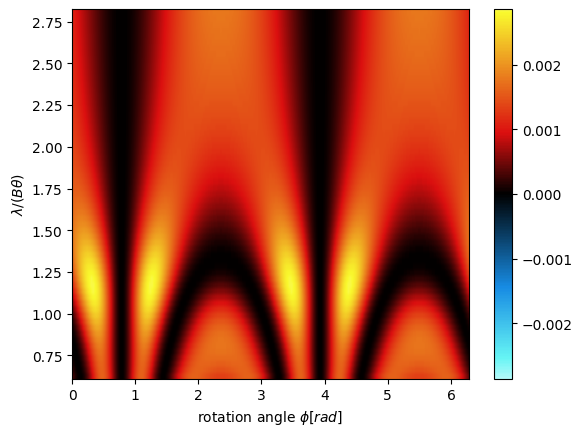

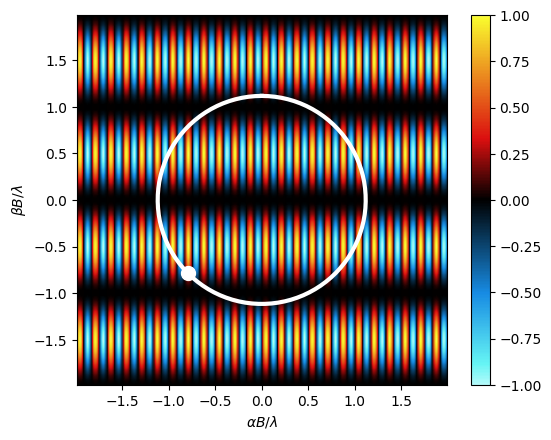

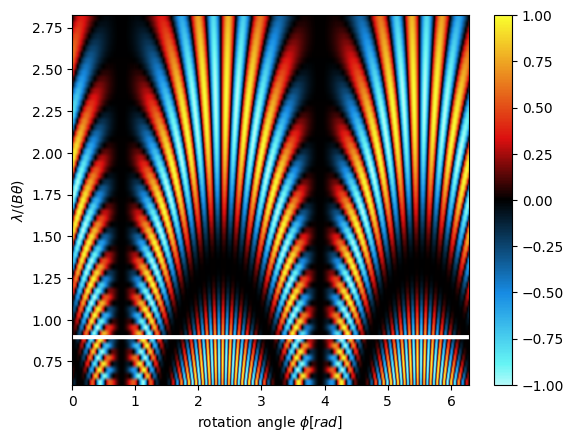

In [9]:
plt.subplots()
planet_color = 'white'#'lightseagreen'
cmap = full_map


plt.imshow(T_SBW_lambda_scenery,extent = (alpha[0]/r0 *inv_l, alpha[-1]/r0 * inv_l, beta[0]/r0 * inv_l, beta[-1]/r0 * inv_l), cmap = cmap, vmin = -1, vmax = 1)
plt.plot(circle[0,:]/r0 * inv_l, circle[1,:]/r0 * inv_l , "-",color = planet_color, lw = 3)
plt.xlabel(r"$\alpha B / \lambda$")
plt.ylabel(r"$\beta B / \lambda$")
plt.colorbar()
plt.scatter(alpha[idx_alpha]/r0 * inv_l, beta[idx_beta]/r0 * inv_l, color = planet_color, s = 100)
plt.savefig('plots/sbw_transmission.png', transparent=True, dpi = 300)
plt.show()
plt.close()

plt.subplots()
plt.imshow(S_SBW_lambda_scenery, extent = (t[0]*Omega, t[-1]*Omega, 1/(inv_range[0]), 1/(inv_range[-1]) ), aspect = 'auto', origin = 'lower', cmap = cmap, vmin = -1, vmax = 1)
plt.plot(t*Omega, 1/(inv_l) * np.ones_like(t) , "-",color = planet_color, lw = 3)
plt.xlabel(r"rotation angle $\phi[rad]$")
plt.ylabel(r"$\lambda / (B \theta)$")
plt.colorbar()
plt.savefig('plots/sbw_point_signal.png', transparent=True, dpi = 300)
plt.show()
plt.close()

plt.subplots()
plt.imshow(S_SBW_lambda_scenery, extent = (t[0]*Omega, t[-1]*Omega, 1/(inv_range[0]), 1/(inv_range[-1]) ), aspect = 'auto', origin = 'lower', cmap = cmap, vmin = -1, vmax = 1)
plt.xlabel(r"rotation angle $\phi[rad]$")
plt.ylabel(r"$\lambda / (B \theta)$")
plt.colorbar()
plt.savefig('plots/sbw_point_signal_.png', transparent=True, dpi = 300)
plt.show()
plt.close()


plt.subplots()
S_SBW_lambda_norm = S_SBW_lambda_scenery / np.sum(S_SBW_lambda_scenery[:,:int(len(t)/2)], axis = 1)[:,None]
plt.imshow(S_SBW_lambda_norm, extent = (t[0]*Omega, t[-1]*Omega, 1/(inv_range[0]), 1/(inv_range[-1]) ), aspect = 'auto', origin = 'lower', cmap = cmap, vmin = -np.max(S_SBW_lambda_norm), vmax = np.max(S_SBW_lambda_norm))
plt.xlabel(r"rotation angle $\phi[rad]$")
plt.ylabel(r"$\lambda / (B \theta)$")
plt.colorbar()
plt.savefig('plots/sbw_point_signal_norm_.png', transparent=True, dpi=300)
plt.show()
plt.close()


plt.subplots()
plt.imshow(T_DBW_lambda_scenery,extent = (alpha[0]/r0 *inv_l, alpha[-1]/r0 * inv_l, beta[0]/r0 * inv_l, beta[-1]/r0 * inv_l), cmap = cmap, vmin = -1, vmax = 1)
plt.plot(circle[0,:]/r0 * inv_l, circle[1,:]/r0 * inv_l , "-",color = planet_color, lw = 3)
plt.xlabel(r"$\alpha B / \lambda$")
plt.ylabel(r"$\beta B / \lambda$")
plt.colorbar()
plt.scatter(alpha[idx_alpha]/r0 * inv_l, beta[idx_beta]/r0 * inv_l, color = planet_color, s = 100)
plt.savefig('plots/dbw_transmission.png', transparent=True,dpi = 300)
plt.show()
plt.close()

plt.subplots()
plt.imshow(S_DBW_lambda_scenery, extent = (t[0]*Omega, t[-1]*Omega, 1/(inv_range[0]), 1/(inv_range[-1]) ), aspect = 'auto', origin = 'lower', cmap = cmap, vmin = -1, vmax = 1)
plt.plot(t*Omega, 1/(inv_l) * np.ones_like(t) , "-",color = planet_color, lw = 3)
plt.xlabel(r"rotation angle $\phi[rad]$")
plt.ylabel(r"$\lambda / (B \theta)$")
plt.colorbar()
plt.savefig('plots/dbw_point_signal.png', transparent=True, dpi=300)
plt.show()
plt.close()




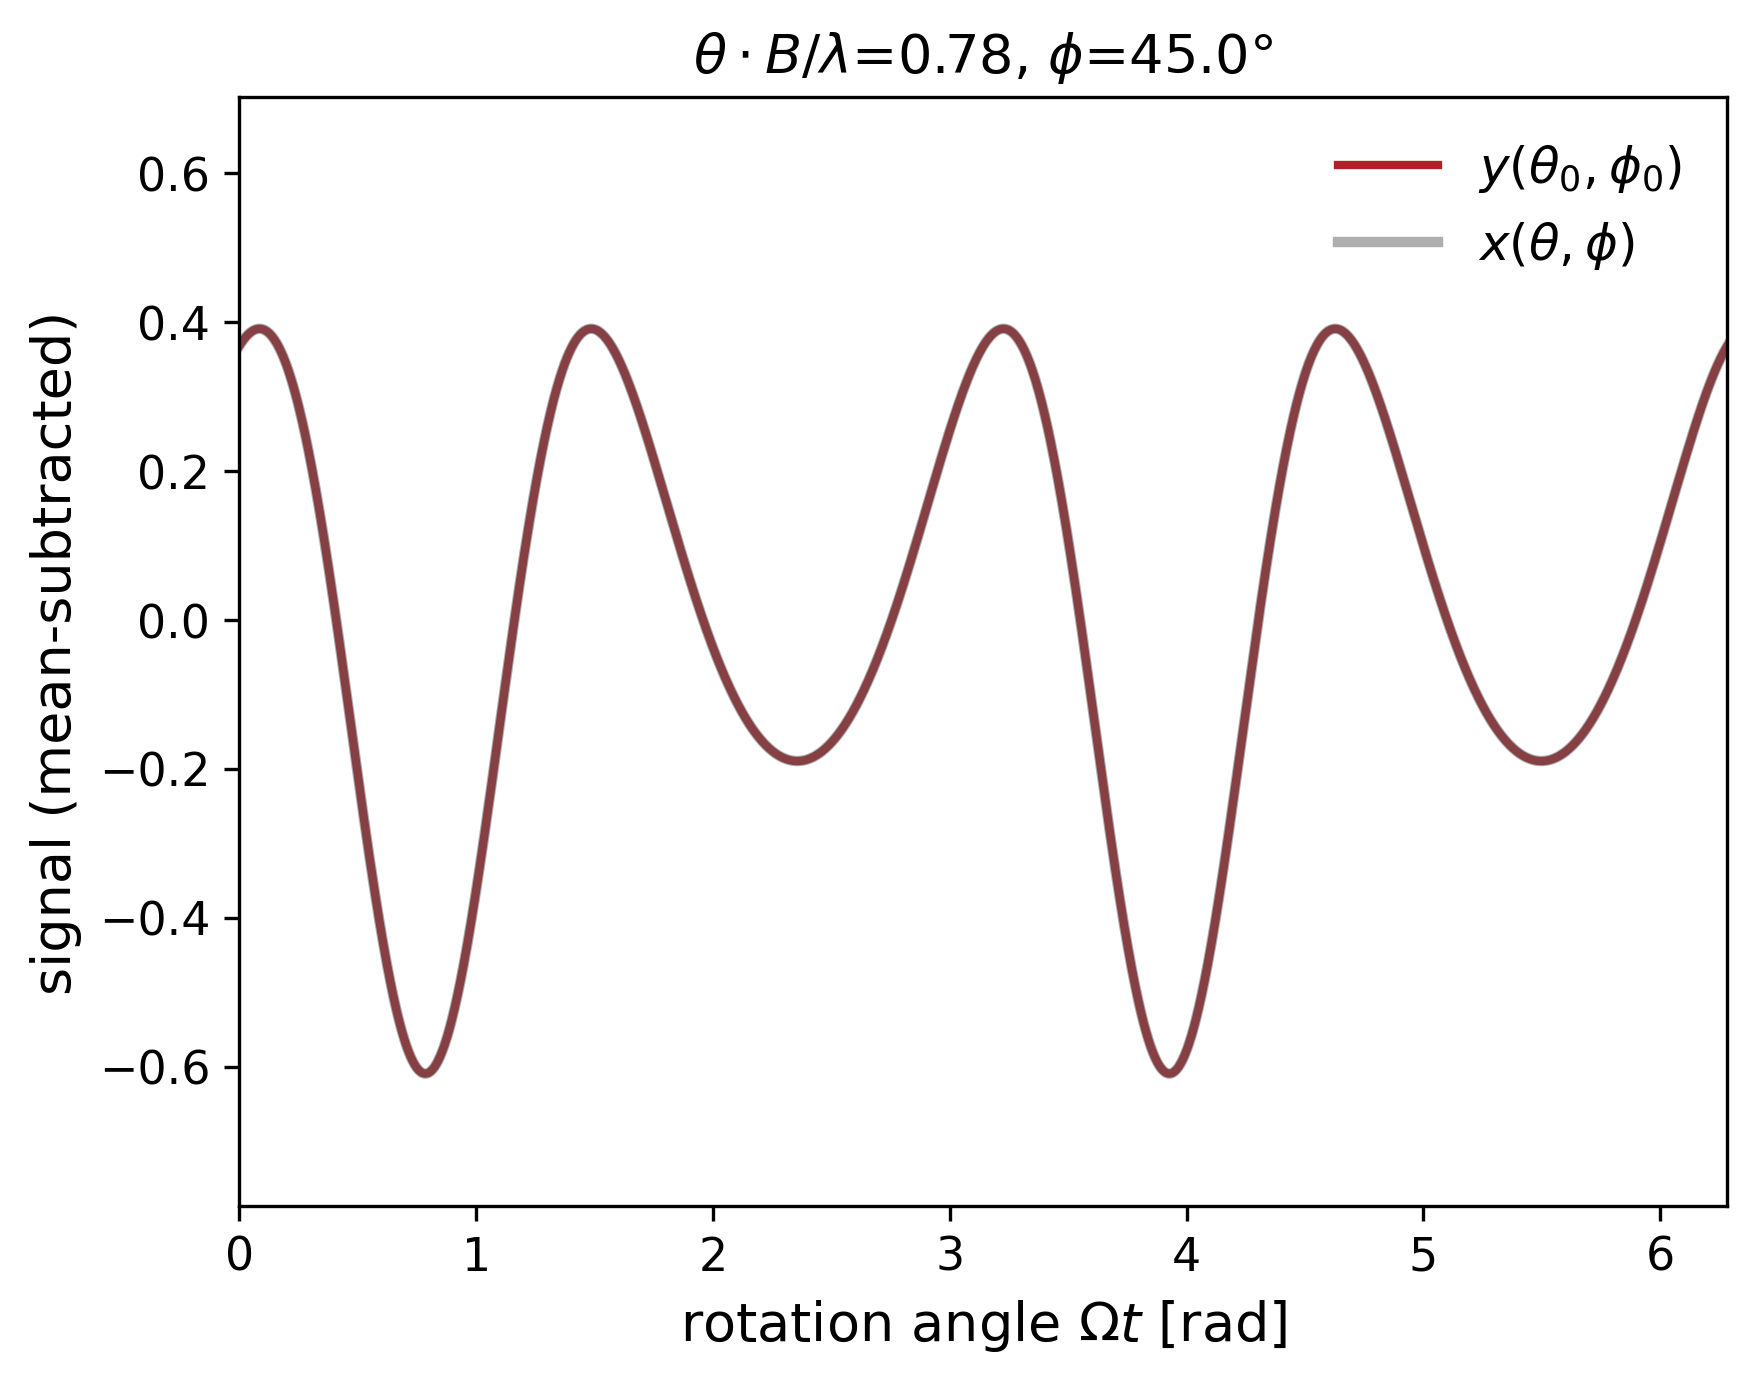

In [10]:

# =================== Animation: default signal vs varying (phi0, theta0) ====================
from PIL import Image

phi0_default = np.pi / 4  # 45 deg -- nonzero so the +/-10% phi0 swing below is visible
theta0_default = 0.2  # [arcsec]
lambda0 = 10e-6  # [m]

alpha0_default = theta0_default * np.cos(phi0_default)
beta0_default = theta0_default * np.sin(phi0_default)
S_default = point_signal_SBW(t, alpha0_default, beta0_default, baseline, lamda_ref=lambda0, Omega=Omega)
S_default = S_default - np.mean(S_default)

# Sweep in two phases, each starting and ending exactly at the default parameters:
# 1) larger theta0 range -- theta0 bulges out to 1.2x default, phi0 dips to 0.9x default, both back
# 2) smaller theta0 range -- theta0 dips in to 0.9x default, phi0 rises to 1.1x default, both back
n_frames_phase = 60
n_frames = 2 * n_frames_phase


def params_for_frame(n):
    if n < n_frames_phase:
        u = n / (n_frames_phase - 1)
        theta0 = theta0_default * (1 + 0.1 * np.sin(np.pi * u))
        phi0 = phi0_default - phi0_default * 0.1 * np.sin(np.pi * u)
        phase = r"larger $\theta_0$ range"
    else:
        u = (n - n_frames_phase) / (n_frames_phase - 1)
        theta0 = theta0_default * (1 - 0.1 * np.sin(np.pi * u))
        phi0 = phi0_default + phi0_default * 0.1 * np.sin(np.pi * u)
        phase = r"smaller $\theta_0$ range"
    return theta0, phi0, phase


# Precompute every frame's signal up front so the y-axis limits can be fixed
# across the whole animation instead of jumping around per frame.
S_var_all = np.zeros((n_frames, len(t)))
theta0_all = np.zeros(n_frames)
phi0_all = np.zeros(n_frames)
phase_all = []
for n in range(n_frames):
    theta0, phi0, phase = params_for_frame(n)
    alpha0 = theta0 * np.cos(phi0)
    beta0 = theta0 * np.sin(phi0)
    S_var = point_signal_SBW(t, alpha0, beta0, baseline, lamda_ref=lambda0, Omega=Omega)
    S_var_all[n] = S_var - np.mean(S_var)
    theta0_all[n] = theta0
    phi0_all[n] = phi0
    phase_all.append(phase)

y_min = min(S_default.min(), S_var_all.min())
y_max = max(S_default.max(), S_var_all.max())
pad = 0.1 * (y_max - y_min)


fig, ax = plt.subplots(dpi=300)
fig.patch.set_alpha(0.0)
ax.patch.set_alpha(0.0)
ax.plot(t * Omega, S_default, "-", color="#AF2228", alpha=1, lw=2, label=rf"$y(\theta_0, \phi_0)$")
line, = ax.plot([], [], "-", color="#5E5E5E", lw=2.5, label=rf"$x(\theta, \phi)$", alpha= 0.5)
ax.set_xlim(t[0] * Omega, t[-1] * Omega)
ax.set_ylim(y_min - pad, y_max + 2*pad)
ax.set_xlabel(r"rotation angle $\Omega t$ [rad]", fontsize=13)
ax.set_ylabel("signal (mean-subtracted)", fontsize=13)
ax.tick_params(labelsize=11)
ax.legend(loc="upper right", framealpha=0, fontsize=12)


def update(n):
    line.set_data(t * Omega, S_var_all[n])
    ax.set_title(rf"$\theta \cdot B / \lambda$={theta0_all[n]*baseline/lambda0*np.pi/3600/180:.2f}, $\phi$={np.degrees(phi0_all[n]):.1f}°", fontsize=13)



TRANSPARENT_IDX = 255 # reserved for transparency
base_palette_img = None
frames = []
for n in range(n_frames):
    update(n)
    fig.canvas.draw()
    rgba = np.asarray(fig.canvas.buffer_rgba()).copy()
    opaque_mask = rgba[:, :, 3] > 127

    rgb_img = Image.fromarray(rgba[:, :, :3], mode="RGB")
    if base_palette_img is None:
        quantized = rgb_img.quantize(colors=TRANSPARENT_IDX, method=Image.Palette.ADAPTIVE, dither=Image.Dither.NONE)
        base_palette_img = quantized
    else:
        quantized = rgb_img.quantize(palette=base_palette_img, dither=Image.Dither.NONE)

    arr = np.array(quantized)
    arr[~opaque_mask] = TRANSPARENT_IDX
    frame = Image.fromarray(arr, mode="P")
    frame.putpalette(base_palette_img.getpalette())
    frames.append(frame)

frames[0].save(
    "plots/signal_sweep.gif",
    save_all=True,
    append_images=frames[1:],
    duration=1000 / 15,  # ~15 fps, matching the previous PillowWriter(fps=15)
    loop=0,
    disposal=2, # clear background before drawing each frame
    transparency=TRANSPARENT_IDX,
    optimize=False,
)

plt.show()
plt.close()


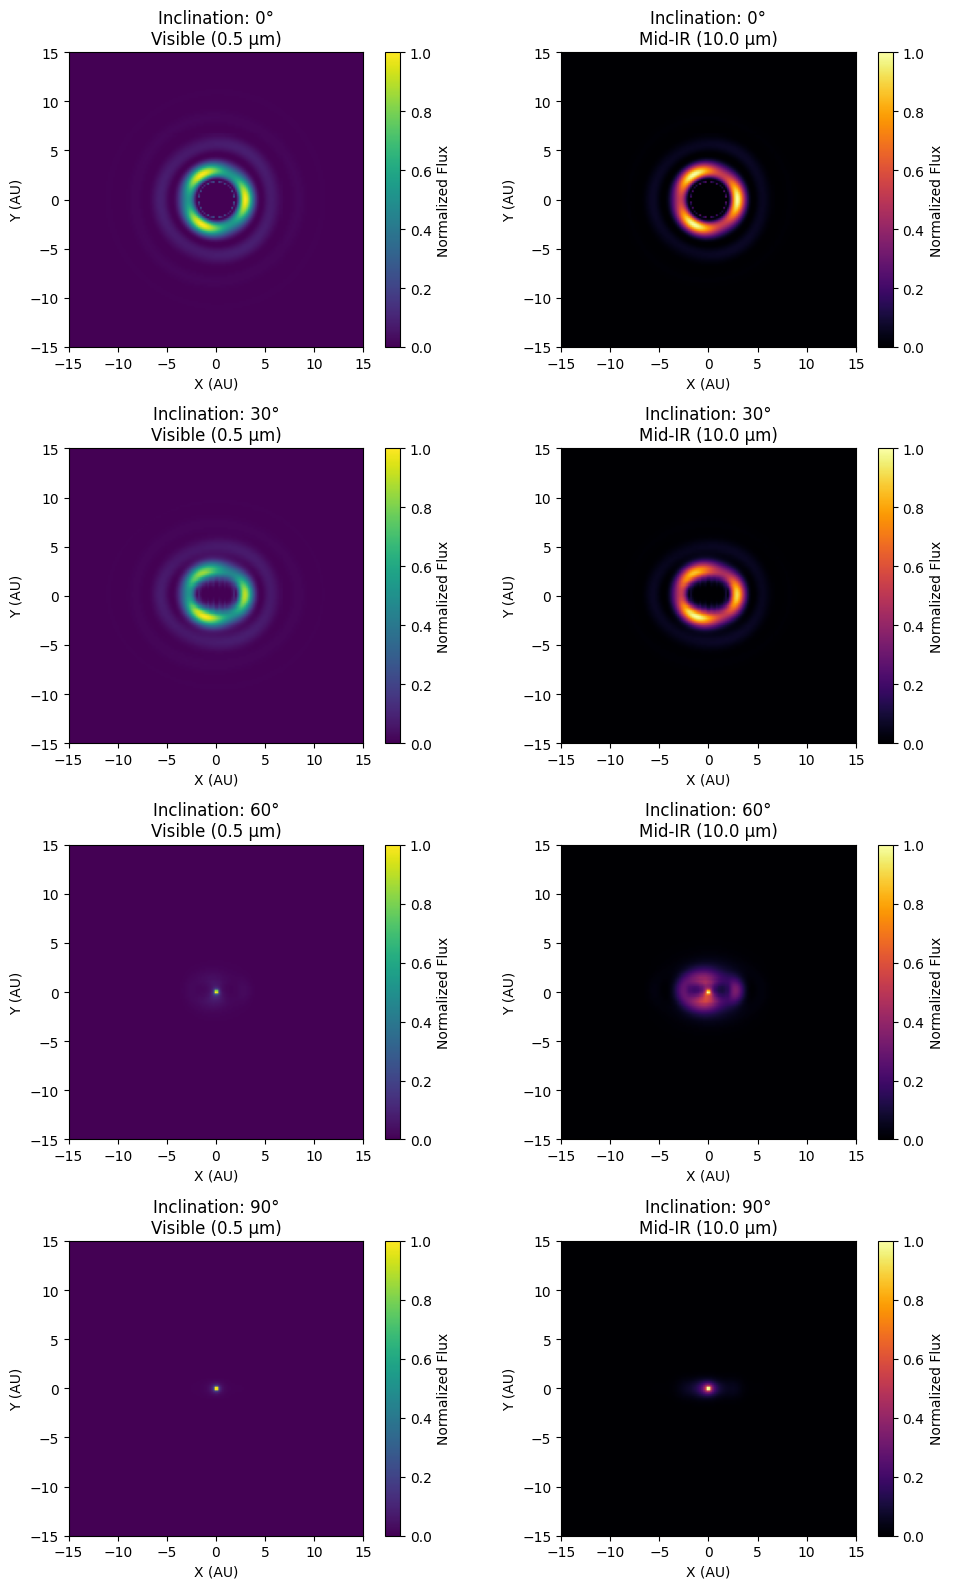

In [11]:

from scipy.special import jn  # Bessel function of first kind

# 1. Setup 3D Grid Parameters (X, Y, Z)
grid_res = 160             # Resolution of the 3D cube
box_size = 15.0            # Boundaries from -15 to +15 AU
axis = np.linspace(-box_size, box_size, grid_res)
X, Y, Z = np.meshgrid(axis, axis, axis, indexing='ij')

# 2. Generate the Base 3D Physical Disk Structure
def generate_3d_disk_density(clumpy=True):
    # Convert flat coordinates to cylindrical coordinates (r, theta, z)
    R_cyl = np.sqrt(X**2 + Y**2) + 1e-6
    Theta = np.arctan2(Y, X)
    
    # Radial structural profile using a 0th-order Bessel function
    k_radial = 1.2
    radial_profile = (jn(0, k_radial * R_cyl))**2 * np.exp(-R_cyl / 6.0)
    radial_profile[R_cyl < 1.8] = 0  # Clear out inner stellar zone
    
    # Structural Clumps using a 3rd-order Bessel-Fourier term
    if clumpy:
        m_clumps = 3
        clump_factor = jn(m_clumps, k_radial * R_cyl) * np.cos(m_clumps * Theta)
        density_profile = radial_profile * (1.0 + 0.8 * clump_factor)
    else:
        density_profile = radial_profile

    # Vertical distribution profile (Gaussian disk scale height H = 0.8 AU)
    H = 0.8 
    vertical_profile = np.exp(-0.5 * (Z / H)**2)
    
    # Combine into a final 3D Density Grid
    return np.clip(density_profile * vertical_profile, 0, None)

# 3. Rotate the 3D Grid & Integrate Along the Line of Sight
def project_disk_at_inclination(density_3d, inclination_deg):
    angle_rad = np.radians(inclination_deg)
    
    # Define standard rotation matrix coordinates around X-axis
    # Rotates the viewing coordinates to look through the cube at an angle
    Y_rot = Y * np.cos(angle_rad) - Z * np.sin(angle_rad)
    Z_rot = Y * np.sin(angle_rad) + Z * np.cos(angle_rad)
    
    # Map coordinates from grid units to array index units
    idx_X = ((X + box_size) / (2.0 * box_size) * (grid_res - 1)).astype(int)
    idx_Y = ((Y_rot + box_size) / (2.0 * box_size) * (grid_res - 1)).astype(int)
    idx_Z = ((Z_rot + box_size) / (2.0 * box_size) * (grid_res - 1)).astype(int)
    
    # Keep indices strictly inside array boundaries
    mask = (idx_Y >= 0) & (idx_Y < grid_res) & (idx_Z >= 0) & (idx_Z < grid_res)
    
    # Map original density values into the newly rotated 3D grid spatial array
    rotated_density = np.zeros_like(density_3d)
    rotated_density[mask] = density_3d[idx_X[mask], idx_Y[mask], idx_Z[mask]]
    
    # Numerical line-of-sight integration: Collapse the Z axis to get a 2D image
    integrated_2d_density = np.sum(rotated_density, axis=2)
    return integrated_2d_density

# 4. Multi-Wavelength Flux Calculations
def calculate_wavelength_flux(density_2d, wavelength_um):
    # Set up a 2D distance map from the central stellar core
    X_2d, Y_2d = np.meshgrid(axis, axis, indexing='ij')
    R_2d = np.sqrt(X_2d**2 + Y_2d**2) + 1e-6
    
    # Radial profile of dust grain temperature: drops with distance (T ~ R^-0.5)
    T_profile = 280.0 * (R_2d / 5.0)**(-0.5)
    
    if wavelength_um < 1.0:
        # Visible Light: Dominated by scattered stellar flux (falls off as 1/R^2)
        flux = density_2d * (1.0 / R_2d**2)
    else:
        # Infrared Light: Thermal dust emission via Planck's Law approximation
        h, c, kB = 6.626e-34, 3.0e8, 1.38e-23
        freq = c / (wavelength_um * 1e-6)
        exponent = (h * freq) / (kB * T_profile)
        blackbody = (2.0 * h * freq**3 / c**2) / (np.exp(np.clip(exponent, 0, 700)) - 1.0)
        flux = density_2d * blackbody
        
    return flux / np.max(flux)  # Normalized output 

# 5. Generate Simulation Grid Matrix (Angles: 0, 30, 60, 90)
inclinations = [0, 30, 60, 90]
wavelengths = {"Visible (0.5 µm)": 0.5, "Mid-IR (10.0 µm)": 10.0}

# Pre-generate our 3D master clumpy disk array
master_3d_disk = generate_3d_disk_density(clumpy=True)

fig, axes = plt.subplots(4, 2, figsize=(10, 16))
plt.subplots_adjust(wspace=0.3, hspace=0.4)

for row_idx, inc in enumerate(inclinations):
    # Perform 3D line-of-sight rotation calculation for this specific angle
    density_surface = project_disk_at_inclination(master_3d_disk, inc)
    
    for col_idx, (wave_name, wave_val) in enumerate(wavelengths.items()):
        ax = axes[row_idx, col_idx]
        
        # Calculate localized physical wavelength emission properties
        flux_map = calculate_wavelength_flux(density_surface, wave_val)
        
        # Plot styling matrix
        cmap = "viridis" if wave_val < 1.0 else "inferno"
        im = ax.imshow(flux_map.T, extent=[-box_size, box_size, -box_size, box_size], 
                       cmap=cmap, origin='lower')
        
        ax.set_title(f"Inclination: {inc}°\n{wave_name}")
        ax.set_xlabel("X (AU)")
        ax.set_ylabel("Y (AU)")
        fig.colorbar(im, ax=ax, label="Normalized Flux")

plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Intensity Pattern (FFT of Aperture)')

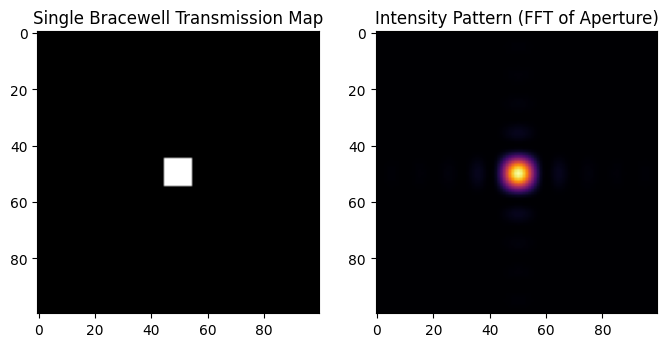

In [12]:
# Single Bracewell Transmission Map

Aperture = np.zeros((100, 100))
Aperture[45:55, 45:55] = 1
Aperture_FFT = np.fft.fftshift(np.fft.fft2(Aperture))
Intensity = np.abs(Aperture_FFT)**2


fig, ax = plt.subplots(1, 2, figsize=(8, 12))
ax[0].imshow(Aperture, cmap='gray')
ax[0].set_title('Single Bracewell Transmission Map')
#ax[0].colorbar()
ax[1].imshow(Intensity, cmap='inferno')
ax[1].set_title('Intensity Pattern (FFT of Aperture)')
#ax[1].colorbar()



(-2.0, 2.0)

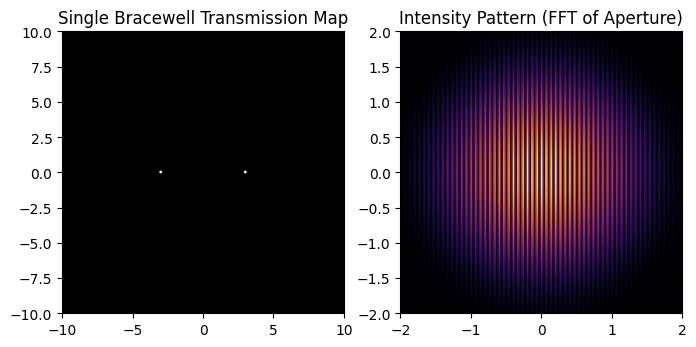

In [13]:
# Single Bracewell Transmission Map
x = np.linspace(-10, 10, 1000)
y = np.linspace(-10, 10, 1000)
X, Y = np.meshgrid(x, y)
Aperture = np.zeros_like(X)
Aperture[np.sqrt((X-3)**2 + Y**2) < 0.1] = 1
Aperture[np.sqrt((X+3)**2 + Y**2) < 0.1] = 1

Aperture_FFT = np.fft.fftshift(np.fft.fft2(Aperture))
Intensity = np.abs(Aperture_FFT)**2

fig, ax = plt.subplots(1, 2, figsize=(8, 12))
ax[0].imshow(Aperture, cmap='gray', extent=[-10, 10, -10, 10])
ax[0].set_title('Single Bracewell Transmission Map')
ax[1].imshow(Intensity, cmap='inferno', extent=[-10, 10, -10, 10])
ax[1].set_title('Intensity Pattern (FFT of Aperture)')
ax[1].set_xlim([-2, 2])
ax[1].set_ylim([-2, 2])

In [14]:
def compute_fft(signal):
    signal_fft = np.fft.rfft(signal, axis = 1)
    amp = 2.0 / N * np.abs(signal_fft) 
    phase = np.angle(signal_fft)
    return amp, phase